# Project 1: teammate's recipe + improvements (one notebook, run top to bottom)

Everything builds on an `r222_80` student (4.34M params) distilled from
`p3_long_s0` + `p3_long_s1` + `teacher_wrn28_10` (already in your `project1_runs`), AutoAugment + Cutout + EMA, 150 epochs.

**Part A: original recipe + gray jitter** (steps 1-4)
1. Smoke test + time estimate (1 min)
2. Validation run on the 45k split: does gray jitter help? (compared with 97.00 / 97.14 without it)
3. Retrain on all 50k for the best validation epoch count
4. Predictions -> `project1_runs/tta_v7/kd3_gray__matched_mc.csv` (**upload 1**)

**Part B: teach that model the group answer on the test images** (steps 5-7)
Original recipe already learns from 3 teachers, but only on the training images. On the test images the 4 models
(3 teachers + the step-3 model) disagree far more often than on validation, and the group's averaged answer is
usually more accurate than any one of them. Step 7 shows the model the 2,000 test
images together with the group's averaged answer for each, and fine-tunes it to give that answer.
Step 6 first checks on validation that this actually raises accuracy.
5. Settings + helpers
6. Validation check (val images play the test set; compared with a control without them)
7. Real run -> `project1_runs/tta_v7/kd3_gray_tdist__matched_mc.csv` (**upload 2**, if step 6 shows a gain)

If Colab disconnects: Run All again. Finished runs are skipped and unfinished ones resume.

In [ ]:
# ---- 1. Setup ----
from google.colab import drive
drive.mount('/content/drive')

import os, json, time, math, copy, zipfile, datetime
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from tqdm.auto import tqdm

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torch.optim.swa_utils import AveragedModel, get_ema_multi_avg_fn
import torchvision
from torchvision.transforms import v2

# Paths: DATA_ZIP is where your data lives; runs/results/cache are written next to it in Drive
DATA_ZIP   = '/content/drive/MyDrive/Fall 2026/CSGY 6953 - Deep Learning/data.zip'
DRIVE_ROOT = os.path.dirname(DATA_ZIP)
DATA_DIR   = '/content/data'                                     # local unzip (fast disk)
CACHE_NPZ  = os.path.join(DRIVE_ROOT, 'project1_cache', 'cifar_uint8.npz')
RUNS_DIR   = os.path.join(DRIVE_ROOT, 'project1_runs')           # per-run history/checkpoints/weights
RESULTS_CSV = os.path.join(RUNS_DIR, 'results.csv')              # one row per finished run
os.makedirs(os.path.dirname(CACHE_NPZ), exist_ok=True)
os.makedirs(RUNS_DIR, exist_ok=True)

device = 'cuda' if torch.cuda.is_available() else 'cpu'
GPU_NAME = torch.cuda.get_device_name(0) if device == 'cuda' else 'cpu'
# bf16 on Ampere+ (A100/L4); fp16 + GradScaler on T4/V100
AMP_DTYPE = torch.bfloat16 if (device == 'cuda' and torch.cuda.get_device_capability()[0] >= 8) else torch.float16
torch.backends.cudnn.benchmark = True
print(f'device={device} ({GPU_NAME}), amp dtype={AMP_DTYPE}, torch {torch.__version__}, torchvision {torchvision.__version__}')

CLASSES = ('plane', 'car', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck')

Mounted at /content/drive
device=cuda (NVIDIA L4), amp dtype=torch.bfloat16, torch 2.11.0+cu130, torchvision 0.26.0+cu130


In [ ]:
# ---- 2. Load all images into memory once (cached as a uint8 .npz in Drive) ----
def load_images(df, img_dir):
    arr = np.empty((len(df), 32, 32, 3), dtype=np.uint8)
    for i, fn in enumerate(tqdm(df['filename'].tolist(), desc=os.path.basename(img_dir))):
        im = np.asarray(Image.open(os.path.join(img_dir, fn)).convert('RGB'))
        assert im.shape == (32, 32, 3), f'unexpected image shape {im.shape} for {fn}'
        arr[i] = im
    return arr

if os.path.exists(CACHE_NPZ):
    d = np.load(CACHE_NPZ, allow_pickle=True)
    X_all_np, Y_all_np, X_test_np, TEST_IDS = d['x_train'], d['y_train'], d['x_test'], d['test_ids']
    print('loaded cache', CACHE_NPZ)
else:
    if not os.path.isdir(DATA_DIR):
        with zipfile.ZipFile(DATA_ZIP) as z:
            z.extractall(DATA_DIR)
    # the zip may contain a top-level folder; find the directory that holds train_labels.csv
    root = next(r for r, _, files in os.walk(DATA_DIR) if 'train_labels.csv' in files)
    train_df = pd.read_csv(os.path.join(root, 'train_labels.csv'))
    test_df  = pd.read_csv(os.path.join(root, 'test.csv'))
    X_all_np = load_images(train_df, os.path.join(root, 'train_images'))
    Y_all_np = train_df['label'].to_numpy().astype(np.int64)
    X_test_np = load_images(test_df, os.path.join(root, 'test_images'))
    TEST_IDS = test_df['id'].to_numpy()
    np.savez(CACHE_NPZ, x_train=X_all_np, y_train=Y_all_np, x_test=X_test_np, test_ids=TEST_IDS)
    print('saved cache', CACHE_NPZ)

# sample_submission.csv (if it's in the zip) is used later to validate the submission format
SAMPLE_SUB = None
with zipfile.ZipFile(DATA_ZIP) as z:
    _m = [n for n in z.namelist() if n.endswith('sample_submission.csv')]
    if _m:
        with z.open(_m[0]) as f:
            SAMPLE_SUB = pd.read_csv(f)
print('sample_submission found' if SAMPLE_SUB is not None else 'no sample_submission.csv in zip')

# NHWC uint8 -> NCHW uint8 torch tensors
X_all  = torch.from_numpy(X_all_np).permute(0, 3, 1, 2).contiguous()
Y_all  = torch.from_numpy(Y_all_np).long()
X_test = torch.from_numpy(X_test_np).permute(0, 3, 1, 2).contiguous()
print('train', tuple(X_all.shape), 'test', tuple(X_test.shape))
print('class counts:', np.bincount(Y_all_np, minlength=10))
# If labels are sorted/grouped in the CSV, contiguous index folds would be badly skewed:
print('fraction of consecutive rows with the same label: %.3f (random order ≈ 0.10)' % (Y_all_np[1:] == Y_all_np[:-1]).mean())

loaded cache /content/drive/MyDrive/Fall 2026/CSGY 6953 - Deep Learning/project1_cache/cifar_uint8.npz
sample_submission found
train (50000, 3, 32, 32) test (2000, 3, 32, 32)
class counts: [5000 5000 5000 5000 5000 5000 5000 5000 5000 5000]
fraction of consecutive rows with the same label: 0.099 (random order ≈ 0.10)


In [ ]:
# ---- 3. Fixed stratified train/val split + normalization stats ----
SPLIT_SEED = 0
VAL_PER_CLASS = 500   # 5k validation images total

rng = np.random.default_rng(SPLIT_SEED)
val_idx = np.concatenate([rng.permutation(np.where(Y_all_np == c)[0])[:VAL_PER_CLASS] for c in range(10)])
train_idx = np.setdiff1d(np.arange(len(Y_all_np)), val_idx)
rng.shuffle(val_idx); rng.shuffle(train_idx)
print(f'train {len(train_idx)}, val {len(val_idx)}')

# per-channel mean/std computed from the training split (reproducible instead of hard-coded)
_x = X_all[train_idx].float().div(255)
MEAN = _x.mean(dim=(0, 2, 3)).view(1, 3, 1, 1).to(device)
STD  = _x.std(dim=(0, 2, 3)).view(1, 3, 1, 1).to(device)
del _x
print('mean', MEAN.flatten().tolist(), 'std', STD.flatten().tolist())

# GPU-resident copies (uint8 is about 150MB for all 50k images, negligible on any Colab GPU)
X_all_gpu, Y_all_gpu = X_all.to(device), Y_all.to(device)
TRAIN_IDX = torch.from_numpy(train_idx).to(device)
VAL_IDX   = torch.from_numpy(val_idx).to(device)
X_test_gpu = X_test.to(device)

train 45000, val 5000
mean [0.49132782220840454, 0.482040673494339, 0.44640830159187317] std [0.24710001051425934, 0.24358436465263367, 0.2615487277507782]


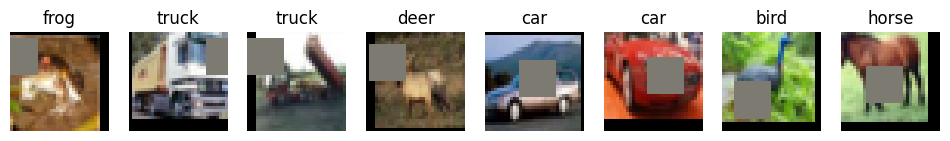

In [ ]:
# ---- 4. Augmentation (batched on GPU) + mixup/cutmix ----
def random_crop(x, pad, mode='constant'):
    # pad by `pad` then take a random 32x32 crop per image (vectorized)
    B, C, H, W = x.shape
    xp = F.pad(x, (pad, pad, pad, pad), mode=mode).permute(0, 2, 3, 1)      # B, H+2p, W+2p, C
    oy = torch.randint(0, 2 * pad + 1, (B,), device=x.device)
    ox = torch.randint(0, 2 * pad + 1, (B,), device=x.device)
    rows = oy[:, None] + torch.arange(H, device=x.device)                      # B, H
    cols = ox[:, None] + torch.arange(W, device=x.device)                      # B, W
    b = torch.arange(B, device=x.device)[:, None, None]
    out = xp[b, rows[:, :, None], cols[:, None, :]]                            # B, H, W, C
    return out.permute(0, 3, 1, 2).contiguous()

def random_flip(x):
    m = torch.rand(x.shape[0], device=x.device) < 0.5
    return torch.where(m[:, None, None, None], x.flip(3), x)

def cutout(x, size):
    # zero a size x size square (in normalized space, i.e. the mean colour) centred at a random pixel
    B, C, H, W = x.shape
    cy = torch.randint(0, H, (B,), device=x.device)
    cx = torch.randint(0, W, (B,), device=x.device)
    ys, xs = torch.arange(H, device=x.device), torch.arange(W, device=x.device)
    my = (ys[None] >= (cy - size // 2)[:, None]) & (ys[None] < (cy + size // 2)[:, None])
    mx = (xs[None] >= (cx - size // 2)[:, None]) & (xs[None] < (cx + size // 2)[:, None])
    mask = my[:, :, None] & mx[:, None, :]
    return x.masked_fill(mask[:, None], 0.0)

def gpu_augment(x_u8, cfg=None, train=False):
    # uint8 NCHW on GPU -> normalized float, channels_last. Augments only when train=True.
    x = x_u8.float().div_(255)
    if train:
        if cfg['crop_pad'] > 0:
            x = random_crop(x, cfg['crop_pad'], cfg['pad_mode'])
        if cfg['flip']:
            x = random_flip(x)
    x = (x - MEAN) / STD
    if train and cfg['cutout'] > 0:
        x = cutout(x, cfg['cutout'])
    return x.contiguous(memory_format=torch.channels_last)

def mix_batch(x, y, cfg):
    # returns (x, y_a, y_b, lam); loss = lam*CE(y_a) + (1-lam)*CE(y_b)
    use_mixup, use_cutmix = cfg['mixup_alpha'] > 0, cfg['cutmix_alpha'] > 0
    if not (use_mixup or use_cutmix) or np.random.rand() > cfg['mix_prob']:
        return x, y, y, 1.0
    perm = torch.randperm(x.shape[0], device=x.device)
    if use_cutmix and (not use_mixup or np.random.rand() < 0.5):
        lam = np.random.beta(cfg['cutmix_alpha'], cfg['cutmix_alpha'])
        H, W = x.shape[2:]
        ch, cw = int(H * math.sqrt(1 - lam)), int(W * math.sqrt(1 - lam))
        cy, cx = np.random.randint(H), np.random.randint(W)
        y1, y2 = np.clip(cy - ch // 2, 0, H), np.clip(cy + ch // 2, 0, H)
        x1, x2 = np.clip(cx - cw // 2, 0, W), np.clip(cx + cw // 2, 0, W)
        x = x.clone()
        x[:, :, y1:y2, x1:x2] = x[perm, :, y1:y2, x1:x2]
        lam = 1 - (y2 - y1) * (x2 - x1) / (H * W)
    else:
        lam = np.random.beta(cfg['mixup_alpha'], cfg['mixup_alpha'])
        x = lam * x + (1 - lam) * x[perm]
    return x, y, y[perm], float(lam)

# Policy augmentations (AutoAugment etc.) are per-image ops, so they run on CPU workers over the
# in-memory uint8 tensor; crop/flip/cutout/normalize still happen on the GPU afterwards.
POLICIES = {
    'autoaugment':    lambda: v2.AutoAugment(v2.AutoAugmentPolicy.CIFAR10),
    'trivialaugment': lambda: v2.TrivialAugmentWide(),
    'randaugment':    lambda: v2.RandAugment(num_ops=2, magnitude=9),
}

class PolicyDataset(Dataset):
    def __init__(self, x_u8, y, policy):
        self.x, self.y, self.t = x_u8, y, POLICIES[policy]()
    def __len__(self): return len(self.x)
    def __getitem__(self, i): return self.t(self.x[i]), self.y[i]

def gpu_batches(x, y, bs, weights=None):
    # shuffled minibatches straight from GPU memory; weights -> weighted sampling with replacement
    idx = (torch.multinomial(weights, len(x), replacement=True) if weights is not None
           else torch.randperm(len(x), device=x.device))
    for i in range(0, len(x) - len(x) % bs, bs):
        j = idx[i:i + bs]
        yield x[j], y[j]

# quick visual check of the augmentation pipeline
_cfg = dict(crop_pad=4, pad_mode='constant', flip=True, cutout=12)
_xa = gpu_augment(X_all_gpu[:8], _cfg, train=True)
_vis = (_xa * STD + MEAN).clamp(0, 1).permute(0, 2, 3, 1).float().cpu().numpy()
fig, ax = plt.subplots(1, 8, figsize=(12, 2))
for i in range(8):
    ax[i].imshow(_vis[i]); ax[i].set_title(CLASSES[int(Y_all[i])]); ax[i].axis('off')
plt.show()

In [ ]:
# ---- 5. Models ----
class SE(nn.Module):
    # squeeze-and-excitation channel attention (adds ~2*C^2/r params per block)
    def __init__(self, c, r=16):
        super().__init__()
        h = max(c // r, 8)
        self.fc1, self.fc2 = nn.Conv2d(c, h, 1), nn.Conv2d(h, c, 1)
    def forward(self, x):
        s = F.adaptive_avg_pool2d(x, 1)
        return x * torch.sigmoid(self.fc2(F.relu(self.fc1(s))))

class PadShortcut(nn.Module):
    # parameter-free "option A" shortcut: subsample spatially + zero-pad extra channels
    def __init__(self, cin, cout, stride):
        super().__init__()
        self.stride, self.extra = stride, cout - cin
        assert self.extra >= 0
    def forward(self, x):
        x = x[:, :, ::self.stride, ::self.stride]
        return F.pad(x, (0, 0, 0, 0, 0, self.extra)) if self.extra else x

def make_shortcut(cin, cout, stride, kind, preact):
    if stride == 1 and cin == cout:
        return nn.Identity()
    if kind == 'pad':
        return PadShortcut(cin, cout, stride)
    conv = nn.Conv2d(cin, cout, 1, stride=stride, bias=False)
    return conv if preact else nn.Sequential(conv, nn.BatchNorm2d(cout))

class BasicBlock(nn.Module):
    # post-activation block (original ResNet): conv-BN-ReLU-conv-BN (+SE) + shortcut, ReLU
    def __init__(self, cin, cout, stride, k=3, shortcut='conv', se=False, drop=0.0):
        super().__init__()
        self.conv1 = nn.Conv2d(cin, cout, k, stride, k // 2, bias=False); self.bn1 = nn.BatchNorm2d(cout)
        self.conv2 = nn.Conv2d(cout, cout, k, 1, k // 2, bias=False);    self.bn2 = nn.BatchNorm2d(cout)
        self.se = SE(cout) if se else nn.Identity()
        self.drop = nn.Dropout(drop) if drop > 0 else nn.Identity()
        self.shortcut = make_shortcut(cin, cout, stride, shortcut, preact=False)
    def forward(self, x):
        out = self.drop(F.relu(self.bn1(self.conv1(x))))
        out = self.se(self.bn2(self.conv2(out)))
        return F.relu(out + self.shortcut(x))

class PreActBlock(nn.Module):
    # pre-activation block (He et al. 2016 / Wide ResNet): BN-ReLU-conv-BN-ReLU-conv (+SE) + shortcut
    def __init__(self, cin, cout, stride, k=3, shortcut='conv', se=False, drop=0.0):
        super().__init__()
        self.bn1 = nn.BatchNorm2d(cin);  self.conv1 = nn.Conv2d(cin, cout, k, stride, k // 2, bias=False)
        self.bn2 = nn.BatchNorm2d(cout); self.conv2 = nn.Conv2d(cout, cout, k, 1, k // 2, bias=False)
        self.se = SE(cout) if se else nn.Identity()
        self.drop = nn.Dropout(drop) if drop > 0 else nn.Identity()
        self.shortcut = make_shortcut(cin, cout, stride, shortcut, preact=True)
        self.needs_proj = not isinstance(self.shortcut, nn.Identity)
    def forward(self, x):
        o = F.relu(self.bn1(x))
        sc = self.shortcut(o) if self.needs_proj else x
        out = self.conv1(o)
        out = self.conv2(self.drop(F.relu(self.bn2(out))))
        return self.se(out) + sc

class ResNet(nn.Module):
    def __init__(self, widths, blocks, block='basic', stem_width=None, kernel=3, stem_kernel=3,
                 shortcut='conv', se=False, block_dropout=0.0, fc_dropout=0.0, num_classes=10):
        super().__init__()
        Block = {'basic': BasicBlock, 'preact': PreActBlock}[block]
        self.preact = block == 'preact'
        stem_width = stem_width or widths[0]
        self.stem = nn.Conv2d(3, stem_width, stem_kernel, 1, stem_kernel // 2, bias=False)
        self.stem_bn = nn.Identity() if self.preact else nn.BatchNorm2d(stem_width)
        layers, cin = [], stem_width
        for s, (w, n) in enumerate(zip(widths, blocks)):
            for b in range(n):
                stride = 2 if (s > 0 and b == 0) else 1
                layers.append(Block(cin, w, stride, kernel, shortcut, se, block_dropout))
                cin = w
        self.layers = nn.Sequential(*layers)
        self.final_bn = nn.BatchNorm2d(cin) if self.preact else nn.Identity()
        self.dropout = nn.Dropout(fc_dropout) if fc_dropout > 0 else nn.Identity()
        self.fc = nn.Linear(cin, num_classes)
        for m in self.modules():
            if isinstance(m, nn.Conv2d):
                nn.init.kaiming_normal_(m.weight, mode='fan_out', nonlinearity='relu')
    def forward(self, x):
        x = self.stem(x)
        x = x if self.preact else F.relu(self.stem_bn(x))
        x = self.layers(x)
        if self.preact:
            x = F.relu(self.final_bn(x))
        x = F.adaptive_avg_pool2d(x, 1).flatten(1)
        return self.fc(self.dropout(x))

# Architecture presets. Names: r<blocks per stage>_<base width>; wrnD_K = Wide ResNet depth D, widen K
ARCH_PRESETS = {
    'baseline_112': dict(widths=[64, 128, 256],      blocks=[1, 1, 2]),      # your original model
    'r222_64':      dict(widths=[64, 128, 256],      blocks=[2, 2, 2]),
    'r223_64':      dict(widths=[64, 128, 256],      blocks=[2, 2, 3]),
    'r343_64':      dict(widths=[64, 128, 256],      blocks=[3, 4, 3]),      # deeper
    'r222_80':      dict(widths=[80, 160, 320],      blocks=[2, 2, 2]),      # wider
    'r2222_40':     dict(widths=[40, 80, 160, 320],  blocks=[2, 2, 2, 2]),   # 4 stages
    'r1111_64':     dict(widths=[64, 128, 256, 512], blocks=[1, 1, 1, 1]),   # half ResNet-18
    'wrn16_4':      dict(widths=[64, 128, 256],      blocks=[2, 2, 2], block='preact', stem_width=16),
    'wrn22_4':      dict(widths=[64, 128, 256],      blocks=[3, 3, 3], block='preact', stem_width=16),
    # teacher for knowledge distillation only (way over budget, never submit this)
    'wrn28_10':     dict(widths=[160, 320, 640],     blocks=[4, 4, 4], block='preact', stem_width=16),
}
ARCH_KEYS = ['widths', 'blocks', 'block', 'stem_width', 'kernel', 'stem_kernel', 'shortcut', 'se',
             'block_dropout', 'fc_dropout']

def arch_kwargs(cfg):
    # preset values, overridden by any explicit (non-None) architecture key in cfg
    kw = dict(ARCH_PRESETS[cfg['arch']]) if cfg.get('arch') else {}
    for k in ARCH_KEYS:
        if cfg.get(k) is not None:
            kw[k] = cfg[k]
    return kw

def build_model(cfg):
    return ResNet(**arch_kwargs(cfg))

def count_params(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

PARAM_LIMIT = 5_000_000
print(f"{'preset':14s} {'params':>10s}")
for name in ARCH_PRESETS:
    n = count_params(build_model({'arch': name}))
    print(f"{name:14s} {n:>10,d} {'' if n <= PARAM_LIMIT else '  <-- over 5M'}")

preset             params
baseline_112    2,408,266 
r222_64         2,777,674 
r223_64         3,958,346 
r343_64         4,623,178 
r222_80         4,337,370 
r2222_40        4,368,690 
r1111_64        4,903,242 
wrn16_4         2,748,890 
wrn22_4         4,298,970 
wrn28_10       36,479,194   <-- over 5M


In [ ]:
# ---- 6. Training engine ----
DEFAULT_CFG = dict(
    name=None, phase='', notes='', seed=0,
    # architecture (preset name + optional overrides; see ARCH_KEYS)
    arch='r222_64', widths=None, blocks=None, block=None, stem_width=None, kernel=None, stem_kernel=None,
    shortcut=None, se=None, block_dropout=None, fc_dropout=None,
    enforce_budget=True,          # assert <= 5M params (turn off only for a KD teacher)
    # data
    train_on_full=False,          # True = train on all 50k (final model), no validation
    subset=None,                  # use only N training images (smoke tests)
    crop_pad=4, pad_mode='constant', flip=True, cutout=0, policy=None,
    mixup_alpha=0.0, cutmix_alpha=0.0, mix_prob=1.0,
    # class-targeted training (keys = class index, e.g. {3: 1.5, 5: 1.5} for cat/dog)
    oversample=None,              # sample these classes x times as often (with replacement)
    class_weights=None,           # multiply these classes' loss by x
    # optimization
    epochs=30, batch_size=256, lr=0.1, momentum=0.9, nesterov=True, weight_decay=5e-4, wd_on_bn=False,
    label_smoothing=0.1, sched='cosine', warmup_epochs=2, milestones=None,
    amp=True, ema=False, ema_decay=0.999,
    # knowledge distillation: teacher = a run name, or a list of run names (ensemble teacher;
    # their temperature-softened probabilities are averaged)
    teacher=None, kd_alpha=0.5, kd_T=4.0,
    # SAM (sharpness-aware minimization): 0 = off; ~0.05-0.1 typical. Doubles the cost of each step.
    sam_rho=0.0,
    # bookkeeping
    ckpt_every=10, save_weights=True, log=True,
)

def make_cfg(**overrides):
    unknown = set(overrides) - set(DEFAULT_CFG)
    assert not unknown, f'unknown config keys: {unknown}'
    cfg = {**DEFAULT_CFG, **overrides}
    assert cfg['name'], 'every run needs a unique name'
    return cfg

def finished_runs():
    return set(pd.read_csv(RESULTS_CSV)['name']) if os.path.exists(RESULTS_CSV) else set()

def autocast():
    return torch.autocast(device_type='cuda' if device == 'cuda' else 'cpu', dtype=AMP_DTYPE,
                          enabled=(device == 'cuda'))

MULTI_SHIFTS = ((0, 0), (2, 0), (-2, 0), (0, 2), (0, -2))

@torch.no_grad()
def predict_probs(model, x_u8, tta=False, bs=1000, pad=4):
    # softmax probabilities.
    #   tta=False   : single view
    #   tta=True    : average with the horizontally flipped image (2 views)
    #   tta='multi' : 5 small shifts x flip (10 views), shifted with black padding like training crops
    model.eval()
    out = []
    for i in range(0, len(x_u8), bs):
        xb = x_u8[i:i + bs]
        if tta == 'multi':
            x01 = F.pad(xb.float() / 255, (pad, pad, pad, pad))
            views = [((x01[:, :, pad + dy:pad + dy + 32, pad + dx:pad + dx + 32] - MEAN) / STD)
                     .contiguous(memory_format=torch.channels_last) for dy, dx in MULTI_SHIFTS]
        else:
            views = [gpu_augment(xb)]
        if tta:
            views = views + [v.flip(3) for v in views]
        with autocast():
            p = sum(model(v).float().softmax(1) for v in views) / len(views)
        out.append(p)
    return torch.cat(out)

def accuracy(model, x_u8, y, tta=False):
    return (predict_probs(model, x_u8, tta).argmax(1) == y).float().mean().item() * 100

def load_run_model(name):
    # load the final saved weights of a finished run (EMA weights if the run used EMA)
    ck = torch.load(os.path.join(RUNS_DIR, name, 'final.pt'), map_location=device, weights_only=False)
    m = build_model(ck['cfg']).to(device).to(memory_format=torch.channels_last)
    m.load_state_dict(ck['state_dict'])
    return m.eval(), ck['cfg']

def load_teachers(teacher):
    names = [teacher] if isinstance(teacher, str) else list(teacher)
    return [load_run_model(n)[0] for n in names]

def ensemble_val_acc(names, tta=True):
    # sanity check before distilling: is the teacher ensemble actually stronger than one student?
    # Only meaningful for runs trained on the 45k split (they have not seen the val images).
    x_val, y_val = X_all_gpu[VAL_IDX], Y_all_gpu[VAL_IDX]
    acc = lambda p: (p.argmax(1) == y_val).float().mean().item() * 100
    probs = {}
    for n in names:
        m, c = load_run_model(n)
        assert not c['train_on_full'], f'{n} was trained on the val images, its val accuracy is meaningless'
        probs[n] = predict_probs(m, x_val, tta=tta)
        print(f'{n:22s} {acc(probs[n]):.2f}')
        del m
    print(f"{'ENSEMBLE':22s} {acc(sum(probs.values())):.2f}")

def set_bn_momentum(model, momentum=None):
    # momentum=0.0 freezes BN running stats (used for SAM's second forward pass); None restores
    for m in model.modules():
        if isinstance(m, nn.modules.batchnorm._BatchNorm):
            if momentum is None:
                m.momentum = getattr(m, '_saved_momentum', m.momentum)
            else:
                m._saved_momentum, m.momentum = m.momentum, momentum

def make_scheduler(opt, cfg, steps_per_epoch):
    total = cfg['epochs'] * steps_per_epoch
    if cfg['sched'] == 'onecycle':
        return torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=cfg['lr'], total_steps=total, pct_start=0.15)
    warm = cfg['warmup_epochs'] * steps_per_epoch
    def f(step):
        if step < warm:
            return (step + 1) / warm
        if cfg['sched'] == 'cosine':
            return 0.5 * (1 + math.cos(math.pi * (step - warm) / max(1, total - warm)))
        if cfg['sched'] == 'multistep':
            return 0.1 ** sum(step >= m * steps_per_epoch for m in cfg['milestones'])
        raise ValueError(cfg['sched'])
    return torch.optim.lr_scheduler.LambdaLR(opt, f)

def run_experiment(cfg, force=False):
    cfg = make_cfg(**cfg)
    name = cfg['name']
    if cfg['log'] and not force and name in finished_runs():
        print(f'[skip] {name} already in results.csv'); return None
    run_dir = os.path.join(RUNS_DIR, name); os.makedirs(run_dir, exist_ok=True)
    torch.manual_seed(cfg['seed']); np.random.seed(cfg['seed'])

    # ---- data ----
    tr_idx = torch.arange(len(X_all_gpu), device=device) if cfg['train_on_full'] else TRAIN_IDX
    if cfg['subset']:
        tr_idx = tr_idx[:cfg['subset']]
    x_tr, y_tr = X_all_gpu[tr_idx], Y_all_gpu[tr_idx]
    x_val, y_val = (None, None) if cfg['train_on_full'] else (X_all_gpu[VAL_IDX], Y_all_gpu[VAL_IDX])
    bs = cfg['batch_size']
    sample_w = None
    if cfg['oversample']:
        cw = torch.ones(10)
        for c, f in cfg['oversample'].items():
            cw[int(c)] = float(f)
        sample_w = cw[y_tr.cpu()]
    if cfg['policy']:
        ds = PolicyDataset(x_tr.cpu(), y_tr.cpu(), cfg['policy'])
        sampler = (torch.utils.data.WeightedRandomSampler(sample_w, len(ds), replacement=True)
                   if sample_w is not None else None)
        loader = DataLoader(ds, batch_size=bs, shuffle=sampler is None, sampler=sampler, drop_last=True,
                            num_workers=0, pin_memory=True)
        train_iter, steps = (lambda: loader), len(loader)
    else:
        w_gpu = sample_w.to(device) if sample_w is not None else None
        train_iter, steps = (lambda: gpu_batches(x_tr, y_tr, bs, w_gpu)), len(x_tr) // bs

    # ---- model / optimizer ----
    model = build_model(cfg).to(device).to(memory_format=torch.channels_last)
    n_params = count_params(model)
    if cfg['enforce_budget']:
        assert n_params <= PARAM_LIMIT, f'{name}: {n_params:,} params exceeds the 5M budget'
    decay = [p for p in model.parameters() if p.ndim > 1 or cfg['wd_on_bn']]
    no_decay = [p for p in model.parameters() if not (p.ndim > 1 or cfg['wd_on_bn'])]
    opt = torch.optim.SGD([{'params': decay, 'weight_decay': cfg['weight_decay']},
                           {'params': no_decay, 'weight_decay': 0.0}],
                          lr=cfg['lr'], momentum=cfg['momentum'], nesterov=cfg['nesterov'])
    sched = make_scheduler(opt, cfg, steps)
    scaler = torch.amp.GradScaler('cuda', enabled=(device == 'cuda' and AMP_DTYPE == torch.float16))
    cls_w = None
    if cfg['class_weights']:
        cls_w = torch.ones(10, device=device)
        for c, f in cfg['class_weights'].items():
            cls_w[int(c)] = float(f)
    criterion = nn.CrossEntropyLoss(weight=cls_w, label_smoothing=cfg['label_smoothing'])
    ema = AveragedModel(model, multi_avg_fn=get_ema_multi_avg_fn(cfg['ema_decay']), use_buffers=True) if cfg['ema'] else None
    teachers = load_teachers(cfg['teacher']) if cfg['teacher'] else []

    # ---- resume from checkpoint if a previous session was interrupted ----
    history, start_epoch, ckpt_path = [], 0, os.path.join(run_dir, 'ckpt.pt')
    if cfg['log'] and os.path.exists(ckpt_path) and not force:
        ck = torch.load(ckpt_path, map_location=device, weights_only=False)
        model.load_state_dict(ck['model']); opt.load_state_dict(ck['opt']); sched.load_state_dict(ck['sched'])
        scaler.load_state_dict(ck['scaler'])
        if ema is not None: ema.load_state_dict(ck['ema'])
        history, start_epoch = ck['history'], ck['epoch'] + 1
        print(f'[resume] {name} from epoch {start_epoch}')

    print(f"[run] {name}: {n_params:,} params, {cfg['epochs']} epochs, {steps} steps/epoch")
    bar = tqdm(range(start_epoch, cfg['epochs']), desc=name, initial=start_epoch, total=cfg['epochs'])
    for epoch in bar:
        model.train()
        if device == 'cuda': torch.cuda.synchronize()
        t0 = time.time()
        loss_sum = torch.zeros((), device=device); correct = torch.zeros((), device=device); seen = 0
        for xb, yb in train_iter():
            xb, yb = xb.to(device, non_blocking=True), yb.to(device, non_blocking=True)
            x = gpu_augment(xb, cfg, train=True)
            x, ya, yb2, lam = mix_batch(x, yb, cfg)
            T = cfg['kd_T']
            t_probs = None
            if teachers:   # averaged temperature-softened teacher probabilities, computed once per batch
                with torch.no_grad(), autocast():
                    t_probs = torch.stack([F.softmax(t(x).float() / T, 1) for t in teachers]).mean(0)

            def compute_loss(out):
                loss = lam * criterion(out, ya) + (1 - lam) * criterion(out, yb2) if lam < 1 else criterion(out, ya)
                if t_probs is not None:
                    kd = F.kl_div(F.log_softmax(out.float() / T, 1), t_probs, reduction='batchmean') * T * T
                    loss = (1 - cfg['kd_alpha']) * loss + cfg['kd_alpha'] * kd
                return loss

            opt.zero_grad(set_to_none=True)
            with autocast():
                out = model(x)
                loss = compute_loss(out)
            scaler.scale(loss).backward()

            if cfg['sam_rho'] > 0:
                # SAM: move to w + e (e = rho * g/||g||, the locally worst-case direction), take the
                # gradient there, return to w, and step with that gradient.
                params = [p for p in model.parameters() if p.grad is not None]
                inv_scale = 1.0 / scaler.get_scale()          # grads are loss-scaled under fp16 AMP
                gnorm = torch.norm(torch.stack([p.grad.norm() * inv_scale for p in params]))
                if torch.isfinite(gnorm):                     # on fp16 overflow skip SAM; scaler skips the step anyway
                    k = cfg['sam_rho'] / (gnorm + 1e-12)
                    with torch.no_grad():
                        eps = [p.grad * inv_scale * k for p in params]
                        for p, e in zip(params, eps):
                            p.add_(e)
                    opt.zero_grad(set_to_none=True)
                    set_bn_momentum(model, 0.0)               # don't update BN running stats twice
                    with autocast():
                        loss2 = compute_loss(model(x))
                    scaler.scale(loss2).backward()
                    set_bn_momentum(model, None)
                    with torch.no_grad():
                        for p, e in zip(params, eps):
                            p.sub_(e)

            scaler.step(opt); scaler.update(); sched.step()
            if ema is not None:
                ema.update_parameters(model)
            loss_sum += loss.detach() * len(yb); correct += (out.argmax(1) == yb).sum(); seen += len(yb)
        if device == 'cuda': torch.cuda.synchronize()
        rec = dict(epoch=epoch + 1, lr=opt.param_groups[0]['lr'], epoch_sec=time.time() - t0,
                   train_loss=loss_sum.item() / seen, train_acc=correct.item() / seen * 100)
        if x_val is not None:
            rec['val_acc'] = accuracy(model, x_val, y_val)
            if ema is not None:
                rec['ema_val_acc'] = accuracy(ema, x_val, y_val)
        history.append(rec)
        bar.set_postfix({k: round(v, 2) for k, v in rec.items() if k in ('train_loss', 'train_acc', 'val_acc', 'ema_val_acc')})
        if cfg['log'] and cfg['ckpt_every'] and (epoch + 1) % cfg['ckpt_every'] == 0 and epoch + 1 < cfg['epochs']:
            torch.save(dict(model=model.state_dict(), opt=opt.state_dict(), sched=sched.state_dict(),
                            scaler=scaler.state_dict(), ema=ema.state_dict() if ema is not None else None,
                            history=history, epoch=epoch), ckpt_path)

    # ---- final metrics (final epoch, no checkpoint picking -> unbiased estimate) ----
    final_model = ema.module if ema is not None else model
    row = dict(name=name, phase=cfg['phase'], notes=cfg['notes'], arch=cfg['arch'], params=n_params,
               epochs=cfg['epochs'], gpu=GPU_NAME,
               sec_per_epoch=round(float(np.mean([h['epoch_sec'] for h in history[-5:]])), 2),
               train_acc=round(history[-1]['train_acc'], 2))
    if x_val is not None:
        row.update(val_acc=round(accuracy(model, x_val, y_val), 2),
                   val_acc_tta=round(accuracy(model, x_val, y_val, tta=True), 2),
                   best_val_acc=round(max(h['val_acc'] for h in history), 2),
                   best_epoch=int(np.argmax([h['val_acc'] for h in history]) + 1))
        if ema is not None:
            row.update(ema_val_acc=round(accuracy(ema, x_val, y_val), 2),
                       ema_val_acc_tta=round(accuracy(ema, x_val, y_val, tta=True), 2))
        # multi-crop TTA of the model that gets saved (EMA weights if EMA is on)
        row['final_val_acc_mtta'] = round(accuracy(final_model, x_val, y_val, tta='multi'), 2)
    row.update(timestamp=datetime.datetime.now().isoformat(timespec='seconds'), cfg_json=json.dumps(cfg))
    print({k: v for k, v in row.items() if k != 'cfg_json'})

    if cfg['log']:
        with open(os.path.join(run_dir, 'history.json'), 'w') as f:
            json.dump(dict(cfg=cfg, history=history, result={k: v for k, v in row.items() if k != 'cfg_json'}), f)
        if cfg['save_weights']:
            torch.save(dict(cfg=cfg, state_dict=final_model.state_dict()), os.path.join(run_dir, 'final.pt'))
        # read-concat-rewrite (not append) so runs with different metric columns stay aligned
        df = pd.read_csv(RESULTS_CSV) if os.path.exists(RESULTS_CSV) else pd.DataFrame()
        pd.concat([df, pd.DataFrame([row])], ignore_index=True).to_csv(RESULTS_CSV, index=False)
        if os.path.exists(ckpt_path):
            os.remove(ckpt_path)
    return final_model

def run_grid(cfgs):
    names = [c['name'] for c in cfgs]
    assert len(names) == len(set(names)), 'duplicate run names in grid'
    for c in cfgs:
        run_experiment(c)
        if device == 'cuda': torch.cuda.empty_cache()

# ---- result viewing helpers ----
SHOW_COLS = ['name', 'arch', 'params', 'epochs', 'val_acc', 'val_acc_tta', 'ema_val_acc', 'ema_val_acc_tta',
             'final_val_acc_mtta', 'best_val_acc', 'train_acc', 'sec_per_epoch', 'notes']

def show_results(phase=None):
    if not os.path.exists(RESULTS_CSV):
        print('no results yet'); return None
    df = pd.read_csv(RESULTS_CSV)
    if phase is not None:
        df = df[df['phase'] == phase]
    cols = [c for c in SHOW_COLS if c in df.columns and df[c].notna().any()]
    return df[cols].sort_values('val_acc', ascending=False).reset_index(drop=True)

def plot_curves(names, key='val_acc'):
    fig, ax = plt.subplots(1, 2, figsize=(13, 4))
    for n in names:
        p = os.path.join(RUNS_DIR, n, 'history.json')
        if not os.path.exists(p): continue
        h = json.load(open(p))['history']
        e = [r['epoch'] for r in h]
        if key in h[0]: ax[0].plot(e, [r[key] for r in h], label=n)
        ax[1].plot(e, [r['train_loss'] for r in h], label=n)
    ax[0].set(xlabel='epoch', ylabel=key, title='validation accuracy'); ax[0].grid(alpha=.3)
    ax[1].set(xlabel='epoch', ylabel='train loss', title='training loss'); ax[1].grid(alpha=.3)
    ax[0].legend(fontsize=8); plt.show()

The first idea is **gray jitter**, and its motivation is from the difference in accuracy between the validation and test images. One suspect is that the test images are not quite the same kind of picture as the training ones. The notebook measured this directly: compared with the training set, the test images have slightly higher contrast (about 8% more) and are slightly brighter (about +0.02 on a 0 to 1 scale), and the test set's average color and spread differ from the training set's too. A network trained only on the original training pictures may be a little thrown by such changes, and it also may lean too heavily on colour.

Gray jitter is the attempt to fix that by training on pictures that have been disturbed in the same ways. During training, half of the images get a random brightness, contrast and saturation change of up to 20%, and one in ten is turned completely greyscale (so color cannot be relied on). If the shift between training and test is part of why accuracy drops, a model that has practiced on such changes should lose less. The question we are testing is whether this helps on the test set, or at least does not hurt it. The notebook cannot see the test labels, so it judges this on validation images, including copies of them that are made grayscale or given the measured train-to-test shift.

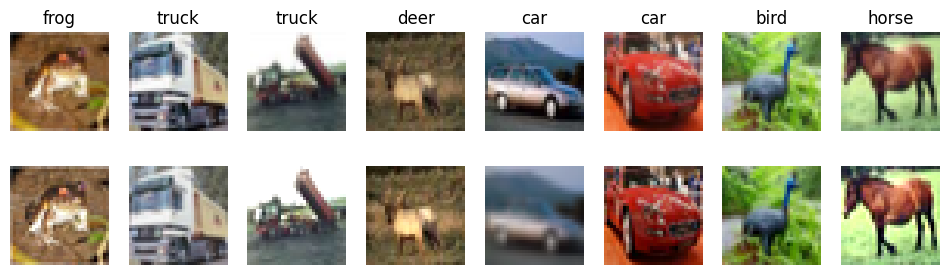

In [ ]:
# ---- 6b. Robustness additions: photometric / degradation augmentation + per-image input normalization ----
# Run right after cell 6, every session. Every new option defaults to OFF, so earlier runs reproduce exactly
# and all existing checkpoints still load.
import io

DEFAULT_CFG.update(
    photo_p=0.0,        # per-image probability of a random brightness/contrast/saturation change
    brightness=0.2,     # multiplicative brightness factor drawn from [1-b, 1+b]
    contrast=0.2,       # contrast factor drawn from [1-c, 1+c] (blend with the image's mean grey level)
    saturation=0.2,     # saturation factor drawn from [1-s, 1+s] (blend with the greyscale image)
    gray_p=0.0,         # per-image probability of converting to greyscale
    degrade_p=0.0,      # per-image probability of a resolution change: half blur (down/up resample), half sharpen
    input_norm=None,    # None = dataset mean/std only; 'image' = the model also standardizes each image by its own mean/std
)

def _gray(x):
    # B,3,H,W in [0,1] -> B,1,H,W luminance
    return 0.299 * x[:, 0:1] + 0.587 * x[:, 1:2] + 0.114 * x[:, 2:3]

def _rand_factor(B, amt, dev):
    return 1 + (torch.rand(B, 1, 1, 1, device=dev) * 2 - 1) * amt

def photometric(x, cfg):
    # random brightness, contrast and saturation (each with its own per-image factor) for a photo_p fraction of images
    B, dev = x.shape[0], x.device
    y = x * _rand_factor(B, cfg['brightness'], dev)
    m = _gray(y).mean(dim=(1, 2, 3), keepdim=True)
    y = (y - m) * _rand_factor(B, cfg['contrast'], dev) + m
    g = _gray(y)
    y = ((y - g) * _rand_factor(B, cfg['saturation'], dev) + g).clamp(0, 1)
    sel = torch.rand(B, 1, 1, 1, device=dev) < cfg['photo_p']
    return torch.where(sel, y, x)

def random_gray(x, p):
    sel = torch.rand(x.shape[0], 1, 1, 1, device=x.device) < p
    return torch.where(sel, _gray(x).expand_as(x), x)

def blur_resample(x, scale):
    # downsample then upsample back: loses fine detail, like a lower-resolution source photo
    H, W = x.shape[2:]
    s = max(8, int(round(H * scale)))
    small = F.interpolate(x, size=(s, s), mode='bilinear', align_corners=False, antialias=True)
    return F.interpolate(small, size=(H, W), mode='bilinear', align_corners=False)

def sharpen(x, amount):
    # unsharp mask: x + amount * (x - blur(x))
    k = torch.tensor([1., 2., 1.], device=x.device, dtype=x.dtype)
    k = ((k[:, None] * k[None, :]) / 16).expand(x.shape[1], 1, 3, 3).contiguous()
    blur = F.conv2d(F.pad(x, (1, 1, 1, 1), mode='replicate'), k, groups=x.shape[1])
    return (x + amount * (x - blur)).clamp(0, 1)

def degrade(x, p):
    # a p/2 fraction of images is blurred (random down/up resample), another p/2 fraction is sharpened
    r = torch.rand(x.shape[0], device=x.device)[:, None, None, None]
    out = torch.where(r < p / 2, blur_resample(x, float(np.random.uniform(0.5, 0.85))), x)
    return torch.where((r >= p / 2) & (r < p), sharpen(x, float(np.random.uniform(0.3, 1.0))), out)

def gpu_augment(x_u8, cfg=None, train=False):
    # (replaces the cell-4 version) uint8 NCHW on GPU -> normalized float, channels_last.
    # Photometric/degradation ops run in [0,1] space before crop/flip; all are skipped when their option is 0.
    x = x_u8.float().div_(255)
    if train:
        if cfg.get('photo_p', 0) > 0:
            x = photometric(x, cfg)
        if cfg.get('gray_p', 0) > 0:
            x = random_gray(x, cfg['gray_p'])
        if cfg.get('degrade_p', 0) > 0:
            x = degrade(x, cfg['degrade_p'])
        if cfg['crop_pad'] > 0:
            x = random_crop(x, cfg['crop_pad'], cfg['pad_mode'])
        if cfg['flip']:
            x = random_flip(x)
    x = (x - MEAN) / STD
    if train and cfg['cutout'] > 0:
        x = cutout(x, cfg['cutout'])
    return x.contiguous(memory_format=torch.channels_last)

class ResNetIN(ResNet):
    # Same network, but each input image is also standardized by its own mean/std (over all pixels and
    # channels). This removes global brightness/contrast differences while keeping colour. It has no
    # parameters or buffers, so the parameter count and state_dict are identical to plain ResNet, and it
    # runs inside the model, so every predict/TTA path gets it automatically.
    def forward(self, x):
        xf = x.float()
        m = xf.mean(dim=(1, 2, 3), keepdim=True)
        s = xf.std(dim=(1, 2, 3), keepdim=True).clamp_min(0.2)   # floor avoids blowing up near-flat images
        x = ((xf - m) / s).to(x.dtype).contiguous(memory_format=torch.channels_last)
        return super().forward(x)

def build_model(cfg):
    # (replaces the cell-5 version) old configs have no 'input_norm' key -> plain ResNet, as before
    cls = ResNetIN if cfg.get('input_norm') == 'image' else ResNet
    return cls(**arch_kwargs(cfg))

# quick visual check: top row original, bottom row with strong photometric + degradation augmentation
_cfg = dict(crop_pad=0, pad_mode='constant', flip=False, cutout=0, photo_p=1.0, brightness=0.2,
            contrast=0.2, saturation=0.2, gray_p=0.1, degrade_p=0.5)
_x8 = X_all_gpu[:8]
_xa = (gpu_augment(_x8, _cfg, train=True) * STD + MEAN).clamp(0, 1)
fig, ax = plt.subplots(2, 8, figsize=(12, 3.2))
for i in range(8):
    ax[0, i].imshow(_x8[i].permute(1, 2, 0).cpu()); ax[0, i].set_title(CLASSES[int(Y_all[i])]); ax[0, i].axis('off')
    ax[1, i].imshow(_xa[i].permute(1, 2, 0).float().cpu()); ax[1, i].axis('off')
plt.show()

In [ ]:
# ---- settings (part A) ----
# Teachers: your teammate's three (all already in your project1_runs).
TEACHERS = ['p3_long_s0', 'p3_long_s1', 'teacher_wrn28_10']
TEACHERS = [t for t in TEACHERS if os.path.exists(os.path.join(RUNS_DIR, t, 'final.pt'))]
print('teachers found:', TEACHERS)
assert len(TEACHERS) == 3, 'missing teacher runs (p3_long_s0, p3_long_s1, teacher_wrn28_10) in ' + RUNS_DIR

EPOCHS = 150                         # teammate's length, so step 2 compares like with like
STUDENT_ARCH = dict(arch='r222_80')  # teammate's best student architecture (4,337,370 params)
SHIFT_AUG = dict(photo_p=0.5, brightness=0.2, contrast=0.2, saturation=0.2, gray_p=0.1)
KD = dict(teacher=TEACHERS, kd_alpha=0.7, kd_T=4.0)
STUDENT_NAME = 'final_kd3_gray_r222_80'
OUT_DIR = os.path.join(RUNS_DIR, 'tta_v7'); os.makedirs(OUT_DIR, exist_ok=True)

teachers found: ['p3_long_s0', 'p3_long_s1', 'teacher_wrn28_10']


## Step 1: smoke test + time estimate (about 1 minute)
One epoch on 5,120 images with the real teachers, not logged. Checks that your checkpoints load in this
engine and extrapolates the time per full epoch.

In [ ]:
SMOKE_N = 5120
_r = run_experiment(make_cfg(name='smoke_kd3_gray', subset=SMOKE_N, epochs=1, warmup_epochs=0, train_on_full=True,
                             policy='autoaugment', cutout=16, ema=True, **STUDENT_ARCH, **SHIFT_AUG, **KD, log=False))
if isinstance(_r, dict) and _r.get('sec_per_epoch'):
    est = _r['sec_per_epoch'] * len(X_all_gpu) / SMOKE_N
    print(f'estimated {est:.0f} s/epoch -> about {est * EPOCHS / 3600:.1f} h for {EPOCHS} epochs on {GPU_NAME} '
          '(first-epoch timing is pessimistic)')

[run] smoke_kd3_gray: 4,337,370 params, 1 epochs, 20 steps/epoch


smoke_kd3_gray:   0%|          | 0/1 [00:00<?, ?it/s]

{'name': 'smoke_kd3_gray', 'phase': '', 'notes': '', 'arch': 'r222_80', 'params': 4337370, 'epochs': 1, 'gpu': 'NVIDIA L4', 'sec_per_epoch': 11.72, 'train_acc': 13.75, 'timestamp': '2026-11-05T16:22:59'}


## Step 2: validation run: does gray jitter help ?
Same recipe, trained on the 45k split only. Scored on the 5k held-out validation images, with multi-crop TTA:
- **clean**: normal val images. On re-collected CIFAR test sets, test accuracy tracks this number, so it's the main signal.
- **grayscale** / **test-like** (val images given the brightness/contrast change measured between train and test): robustness to the shift.

Reference without gray jitter (same recipe, seed 0, from your teammate's notebook output): `p5_kd_ens3_r222_80`
clean **97.00** (multi-crop); a second seed scored 97.14. Seed-to-seed noise is about +/-0.2, so gray jitter clearly
helps only if clean is about 97.2 or higher, and it's neutral if clean stays around 97.0 while grayscale/test-like go up.

**How the gray jitter experiment is carried out.** Everything is held fixed except the augmentation, so that any change in accuracy can be put down to gray jitter. The student, its 150-epoch length, the three teachers, the distillation settings, AutoAugment, Cutout and EMA are all the teammate's. Gray jitter is applied on the GPU to each batch of training images before the usual random crop and flip. For the images chosen (50% of them), a random brightness factor between 0.8 and 1.2 multiplies the pixel values, a random contrast factor between 0.8 and 1.2 stretches the pixels away from or towards the image's own average grey level, and a random saturation factor between 0.8 and 1.2 pushes the colours away from or towards the greyscale version of the image. Separately, 10% of images are replaced by their greyscale version. The student is trained on the 45k split, then scored on the 5k validation images shown three ways (normal, greyscale, and with the measured train-to-test shift), and compared with the students trained without gray jitter. If it looks useful, the same recipe is retrained on all 50k images for the best epoch count (step 3) and used to predict the test set (step 4).

**The gray jitter run.** This trains the student with gray jitter on the 45k split only, so it can be scored on the 5k validation images that it never sees. Apart from the gray jitter, every setting is the original recipe. The original student trained the same way scored 97.00 on validation (and 97.14 with a second seed), so the difference between those numbers and this run's is the effect of gray jitter. Seed-to-seed noise is about 0.2 points, so a difference smaller than that cannot be called a real improvement.

In [ ]:
VAL_NAME = f'p8_kd3_gray_val_e{EPOCHS}_r222_80'   # epoch count in the name: a resume never mixes lengths
run_experiment(make_cfg(name=VAL_NAME, phase='p8', epochs=EPOCHS, seed=0, train_on_full=False,
                        policy='autoaugment', cutout=16, ema=True, **STUDENT_ARCH, **SHIFT_AUG, **KD,
                        notes='VAL run: KD from ' + '+'.join(TEACHERS) + ' | photometric + grayscale p=0.1'))

[run] p8_kd3_gray_val_e150_r222_80: 4,337,370 params, 150 epochs, 175 steps/epoch


p8_kd3_gray_val_e150_r222_80:   0%|          | 0/150 [00:00<?, ?it/s]

{'name': 'p8_kd3_gray_val_e150_r222_80', 'phase': 'p8', 'notes': 'VAL run: KD from p3_long_s0+p3_long_s1+teacher_wrn28_10 | photometric + grayscale p=0.1', 'arch': 'r222_80', 'params': 4337370, 'epochs': 150, 'gpu': 'NVIDIA L4', 'sec_per_epoch': 39.71, 'train_acc': 94.38, 'val_acc': 96.86, 'val_acc_tta': 97.08, 'best_val_acc': 96.88, 'best_epoch': 135, 'ema_val_acc': 96.72, 'ema_val_acc_tta': 97.1, 'final_val_acc_mtta': 97.24, 'timestamp': '2026-11-05T18:04:07'}


ResNet(
  (stem): Conv2d(3, 80, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
  (stem_bn): BatchNorm2d(80, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (layers): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(80, 80, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(80, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv2): Conv2d(80, 80, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(80, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (se): Identity()
      (drop): Identity()
      (shortcut): Identity()
    )
    (1): BasicBlock(
      (conv1): Conv2d(80, 80, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(80, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv2): Conv2d(80, 80, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2):

In [ ]:
# score the val run and your other 45k-split models on clean / grayscale / test-like validation images
xv, yv = X_all_gpu[VAL_IDX], Y_all_gpu[VAL_IDX]
x01 = xv.float() / 255
gray = (0.299 * x01[:, 0:1] + 0.587 * x01[:, 1:2] + 0.114 * x01[:, 2:3])
gmean = gray.mean(dim=(1, 2, 3), keepdim=True)
to_u8 = lambda t: (t.clamp(0, 1) * 255).round().to(torch.uint8)
VAL_VIEWS = {'clean': xv, 'grayscale': to_u8(gray.expand_as(x01)), 'test-like': to_u8((x01 - gmean) * 1.08 + gmean + 0.02)}
REFERENCE = {'p5_kd_ens3_r222_80 (teammate, no gray, seed 0)': 97.00, 'p6_kd3_s1_r222_80 (teammate, no gray, seed 1)': 97.14}

rows = []
for run in [VAL_NAME, 'p3_long_s0', 'p3_long_s1', 'p3_kd_s0']:
    if not os.path.exists(os.path.join(RUNS_DIR, run, 'final.pt')):
        continue
    m, c = load_run_model(run)
    if c.get('train_on_full'):
        continue                      # saw the val images, its val accuracy would be meaningless
    rows.append({'run': run, **{k: round(accuracy(m, v, yv, tta='multi'), 2) for k, v in VAL_VIEWS.items()}})
    del m
display(pd.DataFrame(rows))
print('reference clean val (multi-crop):', REFERENCE)
new_clean = rows[0]['clean'] if rows and rows[0]['run'] == VAL_NAME else None
if new_clean is not None:
    verdict = ('helps' if new_clean >= 97.2 else 'about neutral' if new_clean >= 96.8 else 'hurts')
    print(f'{VAL_NAME}: clean {new_clean:.2f} vs 97.00/97.14 without gray jitter -> gray jitter {verdict} on clean val')

,run,clean,grayscale,test-like
0,p8_kd3_gray_val_e150_r222_80,97.24,95.04,97.18
1,p3_long_s0,97.40,94.86,97.32
2,p3_long_s1,96.96,94.64,97.00
3,p3_kd_s0,97.16,94.54,97.18


reference clean val (multi-crop): {'p5_kd_ens3_r222_80 (teammate, no gray, seed 0)': 97.0, 'p6_kd3_s1_r222_80 (teammate, no gray, seed 1)': 97.14}
p8_kd3_gray_val_e150_r222_80: clean 97.24 vs 97.00/97.14 without gray jitter -> gray jitter helps on clean val


**How to read this table.** The same validation images are shown to each model in three ways. `clean` is the normal validation images and is the main signal, because on re-collected versions of this kind of dataset, test accuracy tracks clean validation accuracy. `grayscale` is the validation images turned fully greyscale, which measures robustness to losing colour. `test-like` is the validation images with the brightness and contrast change that was measured between the training and test sets (contrast times 1.08, brightness plus 0.02).

**Result.** The gray jitter student scores 97.24 on clean validation, against 97.00 and 97.14 for the teammate's students without it. The notebook's rule counts 97.2 or higher as an improvement, so it just clears that bar, but the margin over the 97.14 seed is only 0.10, which is inside the noise. On the greyscale view it is the best of the four models listed (95.04, against 94.5 to 94.9), so it does gain some robustness to colour loss. On the test-like view it scores 97.18, which is the same as the teammate's `p3_kd_s0` model without gray jitter (97.18) and below the two-ResNet teachers' best (97.32). So gray jitter did no harm and may have helped slightly, but the evidence is weak.

## Step 3: retrain on all 50k images for the best validation epoch count
Reads the per-epoch validation history of step 2, takes the epoch with the best EMA val accuracy, and trains the submission model on all 50k images for that many epochs.

In [ ]:
# pick the epoch count from the validation run: the epoch where the EMA weights (what gets saved and
# submitted) had the best val accuracy, then retrain on all 50k for that many epochs
with open(os.path.join(RUNS_DIR, VAL_NAME, 'history.json')) as f:
    hist = json.load(f)['history']
key = 'ema_val_acc' if 'ema_val_acc' in hist[0] else 'val_acc'
accs = [h[key] for h in hist]
FINAL_EPOCHS = len(accs) - int(np.argmax(accs[::-1]))   # on ties, the later epoch
print(f'{VAL_NAME}: best {key} {max(accs):.2f} at epoch {FINAL_EPOCHS} of {len(hist)} '
      f'(last epoch {accs[-1]:.2f}) -> final run uses {FINAL_EPOCHS} epochs')
# the LR schedule is cosine over the run length, so a shorter run still anneals fully by its last epoch

STUDENT_NAME = f'final_kd3_gray_e{FINAL_EPOCHS}_r222_80'   # epoch count in the name: a resume never mixes lengths
STUDENT = make_cfg(name=STUDENT_NAME, phase='final', epochs=FINAL_EPOCHS, seed=0, train_on_full=True,
                   policy='autoaugment', cutout=16, ema=True, **STUDENT_ARCH, **SHIFT_AUG, **KD,
                   notes=f'KD from ' + '+'.join(TEACHERS) + f' | photometric + grayscale p=0.1 | {FINAL_EPOCHS} ep (best val epoch)')
run_experiment(STUDENT)

p8_kd3_gray_val_e150_r222_80: best ema_val_acc 96.90 at epoch 137 of 150 (last epoch 96.72) -> final run uses 137 epochs
[run] final_kd3_gray_e137_r222_80: 4,337,370 params, 137 epochs, 195 steps/epoch


final_kd3_gray_e137_r222_80:   0%|          | 0/137 [00:00<?, ?it/s]

{'name': 'final_kd3_gray_e137_r222_80', 'phase': 'final', 'notes': 'KD from p3_long_s0+p3_long_s1+teacher_wrn28_10 | photometric + grayscale p=0.1 | 137 ep (best val epoch)', 'arch': 'r222_80', 'params': 4337370, 'epochs': 137, 'gpu': 'NVIDIA L4', 'sec_per_epoch': 44.32, 'train_acc': 94.07, 'timestamp': '2026-11-05T19:46:03'}


ResNet(
  (stem): Conv2d(3, 80, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
  (stem_bn): BatchNorm2d(80, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (layers): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(80, 80, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(80, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv2): Conv2d(80, 80, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(80, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (se): Identity()
      (drop): Identity()
      (shortcut): Identity()
    )
    (1): BasicBlock(
      (conv1): Conv2d(80, 80, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(80, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv2): Conv2d(80, 80, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2):

## Step 4: predict with domain-matched normalization + multi-crop TTA
Same weights, but the test images are normalised with the test set's own per-channel mean/std. No BatchNorm changes. Writes `kd3_gray__plain.csv` and `kd3_gray__matched_mc.csv` to `project1_runs/tta_v7/`.

**Why two prediction files.** The test images' color statistics differ slightly from the training set's, so besides the standard version (`plain`) we also write one where each test image is normalised using the test set's own mean and standard deviation (`matched_mc`), which has been the best trick so far. Both use multi-crop test-time augmentation. `predict_with_stats` swaps the global mean and standard deviation only for the duration of the call and always restores them. The two files differ on 14 of the 2,000 test images, so the choice matters little for this model. The new `matched_mc` predictions differ from your previous best submission on 115 images (5.8%). The notebook's own rule of thumb is that fewer than about 20 differing images cannot move the score, so this one can.

In [ ]:
TRAIN_MEAN, TRAIN_STD = MEAN.clone(), STD.clone()
TEST_MEAN = (X_test_gpu.float() / 255).mean(dim=(0, 2, 3), keepdim=True)
TEST_STD = (X_test_gpu.float() / 255).std(dim=(0, 2, 3), keepdim=True)

def predict_with_stats(model, x_u8, mean, std, tta='multi'):
    # predict_probs / gpu_augment read the global MEAN/STD, so swap them in and always restore
    global MEAN, STD
    MEAN, STD = mean, std
    try:
        return predict_probs(model, x_u8, tta=tta)
    finally:
        MEAN, STD = TRAIN_MEAN, TRAIN_STD

def save_sub(preds, path):
    sub = pd.DataFrame({'id': TEST_IDS, 'label': preds.astype(int)})
    assert len(sub) == len(TEST_IDS) and sub['id'].is_unique and sub['label'].between(0, 9).all()
    if SAMPLE_SUB is not None:
        assert list(sub.columns) == list(SAMPLE_SUB.columns) and set(sub['id']) == set(SAMPLE_SUB['id'])
    sub.to_csv(path, index=False)
    print('wrote', path, '| class counts', np.bincount(preds, minlength=10))

student, _ = load_run_model(STUDENT_NAME)
n = count_params(student)
assert n <= PARAM_LIMIT
print(f'{STUDENT_NAME}: {n:,} trainable params')
plain = predict_with_stats(student, X_test_gpu, TRAIN_MEAN, TRAIN_STD).argmax(1).cpu().numpy()
matched = predict_with_stats(student, X_test_gpu, TEST_MEAN, TEST_STD).argmax(1).cpu().numpy()
save_sub(plain, os.path.join(OUT_DIR, 'kd3_gray__plain.csv'))
save_sub(matched, os.path.join(OUT_DIR, 'kd3_gray__matched_mc.csv'))
print(f'matched vs plain: {(matched != plain).sum()} images differ')

# how different is it from your previous best? (fewer than ~20 differing images = can't move the score)
prev = os.path.join(RUNS_DIR, 'tta_v3', 'gj__matched.csv')
if os.path.exists(prev):
    d = (pd.read_csv(prev)['label'].values != matched).sum()
    print(f'kd3_gray__matched_mc vs your gj__matched: {d} images differ ({d / len(matched) * 100:.1f}%)')
pd.read_csv(os.path.join(OUT_DIR, 'kd3_gray__matched_mc.csv')).to_csv('submission.csv', index=False)
print('copied kd3_gray__matched_mc -> submission.csv (local, for download)')

final_kd3_gray_e137_r222_80: 4,337,370 trainable params
wrote /content/drive/MyDrive/Fall 2026/CSGY 6953 - Deep Learning/project1_runs/tta_v7/kd3_gray__plain.csv | class counts [175 216 210 200 197 213 179 206 205 199]
wrote /content/drive/MyDrive/Fall 2026/CSGY 6953 - Deep Learning/project1_runs/tta_v7/kd3_gray__matched_mc.csv | class counts [174 214 212 200 197 210 182 204 206 201]
matched vs plain: 14 images differ
kd3_gray__matched_mc vs your gj__matched: 115 images differ (5.8%)
copied kd3_gray__matched_mc -> submission.csv (local, for download)


## Part B, step 5: settings + helpers

**Why fine-tune on the unlabelled test images.** The group of four models (the two ResNet teachers, the WRN-28-10, and the student from step 3) is more accurate than any single member, because averaging the probabilities of several networks cancels out some of their individual mistakes. The student already learns from the three teachers, but only on the training images, where it is nearly perfect and has little left to learn. The images where the models actually disagree are the test images. The four models disagree far more often on the test images than on validation, and that the group's averaged answer is usually more accurate than any one model. The test images have no labels, but the group can still predict them, and its averaged probabilities carry more information than one hard guess. On an ambiguous image the group might say "70% cat, 25% dog" while the student confidently says "dog".

First, the group predicts the 2,000 test images and we average the probabilities for each one, which gives a soft target. We then build a training set from the 50k labelled images (with their real labels, lightly smoothed) plus the 2,000 test images (with the soft targets in place of labels). Finally we fine-tune the student on that set for 15 epochs at a small learning rate of 0.01. The submitted model is still the single 4.34M student. Each test image appears five times per epoch (`UNL_REPEAT = 5`), giving 10k unlabelled samples next to 50k labelled ones, which is enough for them to matter while the real labels keep the student anchored. The fine-tuning augmentation matches the original training, gray jitter included (`FT_AUG`). This cell defines the settings and helper functions, and step 6 first checks on validation that the whole procedure helps.

In [ ]:
# ---- settings (part B) ----
VAL_TEACHERS = TEACHERS + [VAL_NAME]          # her 3 teachers + the step-2 model (none saw the val images)
TEST_TEACHERS = TEACHERS + [STUDENT_NAME]     # her 3 teachers + the step-3 model
print('validation check: base', VAL_NAME, '| group', VAL_TEACHERS)
print('real run        : base', STUDENT_NAME, '| group', TEST_TEACHERS)
FT_EPOCHS = 15
FT_LR = 0.01
UNL_REPEAT = 5                # each unlabelled image appears 5x per epoch (2,000 x 5 = 10k next to 50k labelled)
FT_AUG = dict(crop_pad=4, pad_mode='constant', flip=True, cutout=16, **SHIFT_AUG)

# ---- helpers (part B) ----
def ensemble_probs(names, x_u8, mean, std):
    # average of the members' multi-crop probabilities
    total = 0
    for n in names:
        m, _ = load_run_model(n)
        total = total + predict_with_stats(m, x_u8, mean, std)
        del m
    if device == 'cuda': torch.cuda.empty_cache()
    return total / len(names)

class SoftTargetDataset(Dataset):
    # uint8 images + a probability vector per image; the CPU policy (AutoAugment) is applied per image
    def __init__(self, x_u8, targets, policy):
        self.x, self.t, self.tf = x_u8, targets, POLICIES[policy]()
    def __len__(self): return len(self.x)
    def __getitem__(self, i): return self.tf(self.x[i]), self.t[i]

def smoothed_onehot(y, eps=0.1):
    t = torch.full((len(y), 10), eps / 10, device=y.device)
    t[torch.arange(len(y), device=y.device), y] += 1 - eps
    return t

def finetune_soft(base_name, new_name, x_lab, y_lab, x_unl=None, t_unl=None, epochs=FT_EPOCHS, lr=FT_LR, seed=0):
    # fine-tune base_name on labelled images (label-smoothed targets) + optional unlabelled images with soft targets
    run_dir = os.path.join(RUNS_DIR, new_name)
    if os.path.exists(os.path.join(run_dir, 'final.pt')):
        print(f'[skip] {new_name} already trained'); return load_run_model(new_name)[0]
    os.makedirs(run_dir, exist_ok=True)
    torch.manual_seed(seed); np.random.seed(seed)
    model, base_cfg = load_run_model(base_name)
    x, t = x_lab, smoothed_onehot(y_lab)
    if x_unl is not None:
        x = torch.cat([x, x_unl.repeat(UNL_REPEAT, 1, 1, 1)])
        t = torch.cat([t, t_unl.to(t.device).repeat(UNL_REPEAT, 1)])
    loader = DataLoader(SoftTargetDataset(x.cpu(), t.cpu(), 'autoaugment'), batch_size=256, shuffle=True,
                        drop_last=True, num_workers=0, pin_memory=True)
    decay = [p for p in model.parameters() if p.ndim > 1]
    no_decay = [p for p in model.parameters() if p.ndim <= 1]
    opt = torch.optim.SGD([{'params': decay, 'weight_decay': 5e-4}, {'params': no_decay, 'weight_decay': 0.0}],
                          lr=lr, momentum=0.9, nesterov=True)
    sched = make_scheduler(opt, dict(epochs=epochs, sched='cosine', warmup_epochs=0, lr=lr), len(loader))
    scaler = torch.amp.GradScaler('cuda', enabled=(device == 'cuda' and AMP_DTYPE == torch.float16))
    ema = AveragedModel(model, multi_avg_fn=get_ema_multi_avg_fn(0.999), use_buffers=True)
    history = []
    for epoch in tqdm(range(epochs), desc=new_name):
        model.train()
        loss_sum, seen, t0 = 0.0, 0, time.time()
        for xb, tb in loader:
            xb, tb = xb.to(device, non_blocking=True), tb.to(device, non_blocking=True)
            with autocast():
                out = model(gpu_augment(xb, FT_AUG, train=True))
            loss = -(tb * F.log_softmax(out.float(), 1)).sum(1).mean()
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.step(opt); scaler.update(); sched.step()
            ema.update_parameters(model)
            loss_sum += loss.item() * len(xb); seen += len(xb)
        history.append(dict(epoch=epoch + 1, train_loss=loss_sum / seen, epoch_sec=time.time() - t0))
    final = ema.module.eval()
    torch.save(dict(cfg=base_cfg, state_dict=final.state_dict()), os.path.join(run_dir, 'final.pt'))
    with open(os.path.join(run_dir, 'history.json'), 'w') as f:
        json.dump(dict(base=base_name, n_unlabelled=0 if x_unl is None else len(x_unl), repeat=UNL_REPEAT,
                       epochs=epochs, lr=lr, history=history), f)
    return final

validation check: base p8_kd3_gray_val_e150_r222_80 | group ['p3_long_s0', 'p3_long_s1', 'teacher_wrn28_10', 'p8_kd3_gray_val_e150_r222_80']
real run        : base final_kd3_gray_e137_r222_80 | group ['p3_long_s0', 'p3_long_s1', 'teacher_wrn28_10', 'final_kd3_gray_e137_r222_80']


## Step 6: validation check
Val images play the test set: the ensemble of `VAL_TEACHERS` predicts them (no labels used), then the step-2 model is
fine-tuned on the 45k labelled images + the val images with those soft targets. The **control** gets the same
fine-tuning on the 45k images only, so any difference between the two comes from the unlabelled images.
The method works if the fine-tuned model clearly beats the control and moves toward the ensemble's accuracy.

In [ ]:
for n in [VAL_NAME] + VAL_TEACHERS:
    assert not load_run_model(n)[1].get('train_on_full'), f'{n} saw the val images; not usable for this check'
xv, yv = X_all_gpu[VAL_IDX], Y_all_gpu[VAL_IDX]
val_targets = ensemble_probs(VAL_TEACHERS, xv, TRAIN_MEAN, TRAIN_STD)
finetune_soft(VAL_NAME, f'{VAL_NAME}_tdist_control', X_all_gpu[TRAIN_IDX], Y_all_gpu[TRAIN_IDX])
finetune_soft(VAL_NAME, f'{VAL_NAME}_tdist', X_all_gpu[TRAIN_IDX], Y_all_gpu[TRAIN_IDX], xv, val_targets)

acc = lambda p: round((p.argmax(1) == yv).float().mean().item() * 100, 2)
rows = [dict(model=f'ensemble of {len(VAL_TEACHERS)} (not submittable)', val_acc=acc(val_targets))]
for name, label in ((VAL_NAME, f'{VAL_NAME} (start)'), (f'{VAL_NAME}_tdist_control', 'fine-tuned, labelled only (control)'),
                    (f'{VAL_NAME}_tdist', 'fine-tuned + unlabelled val with ensemble targets')):
    m, _ = load_run_model(name)
    rows.append(dict(model=label, val_acc=acc(predict_with_stats(m, xv, TRAIN_MEAN, TRAIN_STD)), params=count_params(m)))
    del m
VAL_TABLE = pd.DataFrame(rows)
display(VAL_TABLE)
gain = VAL_TABLE.val_acc.iloc[3] - VAL_TABLE.val_acc.iloc[2]
print(f'effect of the unlabelled images: {gain:+.2f} points over the control '
      f'({gain / 100 * len(yv):+.0f} of {len(yv)} images; seed noise is about +/-0.2)')

p8_kd3_gray_val_e150_r222_80_tdist_control:   0%|          | 0/15 [00:00<?, ?it/s]

p8_kd3_gray_val_e150_r222_80_tdist:   0%|          | 0/15 [00:00<?, ?it/s]

,model,val_acc,params
0,ensemble of 4 (not submittable),97.48,NaN
1,p8_kd3_gray_val_e150_r222_80 (start),97.24,4337370.0
2,"fine-tuned, labelled only (control)",97.04,4337370.0
3,fine-tuned + unlabelled val with ensemble targets,97.44,4337370.0


effect of the unlabelled images: +0.40 points over the control (+20 of 5000 images; seed noise is about +/-0.2)


## Step 7: the real run on the test images

In [ ]:
test_targets = ensemble_probs(TEST_TEACHERS, X_test_gpu, TEST_MEAN, TEST_STD)   # matched normalisation, as in your best files
print(f'ensemble mean confidence on test: {test_targets.max(1).values.mean():.3f}')
ALL_IDX = torch.arange(len(X_all_gpu), device=device)
TDIST_NAME = f'{STUDENT_NAME}_tdist'
student = finetune_soft(STUDENT_NAME, TDIST_NAME, X_all_gpu[ALL_IDX], Y_all_gpu[ALL_IDX], X_test_gpu, test_targets)
n = count_params(student); assert n <= PARAM_LIMIT
print(f'{TDIST_NAME}: {n:,} trainable params')

preds = {}
for tag, (mean, std) in (('plain', (TRAIN_MEAN, TRAIN_STD)), ('matched_mc', (TEST_MEAN, TEST_STD))):
    preds[tag] = predict_with_stats(student, X_test_gpu, mean, std).argmax(1).cpu().numpy()
    save_sub(preds[tag], os.path.join(OUT_DIR, f'kd3_gray_tdist__{tag}.csv'))
ens = test_targets.argmax(1).cpu().numpy()
base_m, _ = load_run_model(STUDENT_NAME)
base = predict_with_stats(base_m, X_test_gpu, TEST_MEAN, TEST_STD).argmax(1).cpu().numpy(); del base_m
p = preds['matched_mc']
print(f'plain vs matched: {(preds["plain"] != p).sum()} images differ')
print(f'fine-tuned vs {STUDENT_NAME} (start): {(p != base).sum()} images differ')
print(f'agreement with the ensemble: start {(base == ens).mean() * 100:.1f}% -> fine-tuned {(p == ens).mean() * 100:.1f}%')
pd.read_csv(os.path.join(OUT_DIR, 'kd3_gray_tdist__matched_mc.csv')).to_csv('submission.csv', index=False)
print('copied kd3_gray_tdist__matched_mc -> submission.csv (local, for download)')

Gray jitter gave a small, uncertain gain: 97.24 on clean validation against 97.00 and 97.14 without it, with somewhat better robustness to greyscale images, but a margin inside the seed noise. Fine-tuning on the unlabelled test images brought the student up to the group's level on the validation rehearsal (97.44 against 97.48), and beat its control by 0.40, although the control itself lost 0.20, so the gain over the starting student is smaller. Whether either idea helps on the real test set is not settled by this notebook, because the real-run cell has no saved output, so the submission files have to be scored to find out.

The numbers in these notes come from the executed run saved in this notebook, and a re-run will differ by roughly the seed noise.